# Which sellers should a limited budget go to first? (Phase 5)

Phase 4 found sellers whose on-time orders are unhappy more often than usual, beyond chance. Olist
can't help every seller at once. This notebook uses **linear programming** (PuLP) to choose which
sellers to include in a pilot under a fixed budget. The data has no costs, so every cost and benefit
is a written-down **assumption**. The output is a ranked list **worth testing**, not a promise of results.

**Contents:** 1. Setup · 2. A tiny example · 3. The seller table · 4. The assumptions ·
5. The model · 6. Model vs simple rules · 7. How much the assumptions matter · 8. The ranked
shortlist · 9. Summary · 10. Limitations

## 1. Setup
**PuLP** lets us describe a choice problem in plain Python: what we can choose, what we want to
maximise, and the limits. A **solver** (here HiGHS, free and open source) then finds the best answer.

In [1]:
import pulp
print("PuLP", pulp.__version__, "| solvers available:", pulp.listSolvers(onlyAvailable=True))

PuLP 4.2.0 | solvers available: ['HiGHS']


## 2. A tiny example (made-up numbers)
Four sellers. Helping each one costs something and is expected to avoid some unhappy orders.
The budget is 10. Which sellers should we pick to avoid the most unhappy orders?

In [2]:
toy = {            # seller: (cost, unhappy orders avoided)  - made-up numbers for the example
    "A": (6, 30),
    "B": (5, 20),
    "C": (5, 20),
    "D": (3, 9),
}
BUDGET = 10

model = pulp.LpProblem("toy", pulp.LpMaximize)                        # we want the biggest benefit
pick = {s: model.add_variable(f"pick_{s}", cat="Binary") for s in toy}  # 1 = help this seller, 0 = don't
model += pulp.lpSum(toy[s][1] * pick[s] for s in toy)                 # goal: total unhappy orders avoided
model += pulp.lpSum(toy[s][0] * pick[s] for s in toy) <= BUDGET       # limit: total cost within budget
result = model.solve(pulp.HiGHS(msg=False))                           # the solver does the maths

chosen = [s for s in toy if pick[s].value() > 0.5]
print("status:", result.status.name, "| chosen:", chosen,
      "| cost:", sum(toy[s][0] for s in chosen), "| avoided:", sum(toy[s][1] for s in chosen))

status: Optimal | chosen: ['B', 'C'] | cost: 10 | avoided: 40


**Why not just take the "best" seller first?** Seller A has the biggest benefit, so a simple
"best first" rule takes A (cost 6), then only D still fits (cost 3): 39 avoided. The model finds
B + C (cost 10): 40 avoided. With a budget, the best *combination* is not always the best items
one by one, and that is the job PuLP does for us.

## 3. The seller table (real data)
The model needs one row per candidate seller. We rebuild the Phase 4 seller test exactly (reviewed,
**on-time**, single-seller, delivered orders; 50+ orders; one-sided binomial test; Holm), then keep
the sellers that are worse than usual beyond chance. For each one we add:
- **excess unhappy orders:** how many more unhappy orders they had than the usual rate would give
  (`unhappy - usual rate × orders`). This is the most a fix could hope to remove.
- **careful excess:** the same, using the low end of the seller's 95% Wilson interval, so a seller
  whose high rate may partly be luck counts for less.
- **months active and orders per month,** so later steps can talk about a pilot lasting a few months.

In [3]:
import sys
from pathlib import Path

import pandas as pd
from scipy import stats
from sqlalchemy import text

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # so "from src..." works when run from notebooks/
from src.db import get_engine

engine = get_engine()

def query(sql: str) -> pd.DataFrame:
    """Run one SQL query and return the result as a table."""
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn)

def holm(p_values: list) -> list:
    """Holm correction for many tests at once (same as notebook 02)."""
    m, order = len(p_values), sorted(range(len(p_values)), key=lambda i: p_values[i])
    adjusted, running = [0.0] * m, 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (m - rank) * p_values[i]))
        adjusted[i] = running
    return adjusted

In [4]:
sellers = query("""
    SELECT f.seller_id, s.state,
           count(*)                             AS orders,     -- reviewed on-time orders
           count(*) FILTER (WHERE f.is_unhappy) AS unhappy,
           min(f.purchase_date) AS first_order, max(f.purchase_date) AS last_order
    FROM analytics.fact_order f
    JOIN analytics.dim_seller s ON s.seller_id = f.seller_id
    WHERE f.n_sellers = 1 AND f.has_review AND f.order_status = 'delivered' AND f.days_late <= 0
    GROUP BY f.seller_id, s.state
""")
usual = sellers["unhappy"].sum() / sellers["orders"].sum()        # usual on-time unhappy rate

tested = sellers[sellers["orders"] >= 50].copy()                  # same 50+ rule as Phase 4
tested["p_value"] = [stats.binomtest(int(u), int(n), usual, alternative="greater").pvalue
                     for u, n in zip(tested["unhappy"], tested["orders"])]
tested["p_holm"] = holm(list(tested["p_value"]))
print(f"usual rate {100 * usual:.2f}% | {len(tested)} sellers tested | "
      f"{(tested['p_holm'] < 0.05).sum()} worse than usual after Holm")

usual rate 8.77% | 393 sellers tested | 24 worse than usual after Holm


In [5]:
cand = tested[tested["p_holm"] < 0.05].copy()                      # the candidates for the pilot
cand["rate_pct"] = 100 * cand["unhappy"] / cand["orders"]
cand["rate_low_pct"] = [100 * stats.binomtest(int(u), int(n)).proportion_ci(method="wilson").low
                        for u, n in zip(cand["unhappy"], cand["orders"])]
cand["excess"] = cand["unhappy"] - usual * cand["orders"]                       # unhappy orders above usual
cand["excess_careful"] = (cand["rate_low_pct"] / 100 - usual) * cand["orders"]  # same, at the interval's low end
days = (pd.to_datetime(cand["last_order"]) - pd.to_datetime(cand["first_order"])).dt.days
cand["months_active"] = (days / 30.44).clip(lower=1)                            # at least 1 month
cand["orders_per_month"] = cand["orders"] / cand["months_active"]
cand["seller"] = cand["seller_id"].str[:8]                                      # short id for display

cand = cand.sort_values("excess", ascending=False).reset_index(drop=True)
cols = ["seller", "state", "orders", "unhappy", "rate_pct", "rate_low_pct",
        "excess", "excess_careful", "months_active", "orders_per_month"]
cand[cols].round(1)

,seller,state,orders,unhappy,rate_pct,rate_low_pct,excess,excess_careful,months_active,orders_per_month
0,7c67e144,SP,870,178,20.5,17.9,101.7,79.5,18.3,47.5
1,6560211a,SP,1680,221,13.2,11.6,73.7,47.9,18.3,91.6
2,2eb70248,SP,162,74,45.7,38.2,59.8,47.7,5.4,30.3
3,4a3ca931,SP,1489,178,12.0,10.4,47.4,24.4,19.6,76.0
4,1ca7077d,SP,87,47,54.0,43.6,39.4,30.3,6.8,12.9
5,d2374cbc,SP,458,74,16.2,13.1,33.8,19.7,18.3,25.0
6,cca3071e,SP,624,87,13.9,11.4,32.3,16.7,22.6,27.6
7,710e3548,PR,124,37,29.8,22.5,26.1,17.0,22.3,5.6
8,897060da,SP,266,49,18.4,14.2,25.7,14.5,16.0,16.7
9,7040e82f,SP,185,40,21.6,16.3,23.8,13.9,11.5,16.1


In [6]:
total, top5 = cand["excess"].sum(), cand["excess"].head(5).sum()
print(f"{len(cand)} candidate sellers | {cand['orders'].sum():,} on-time orders | "
      f"{total:.0f} excess unhappy orders ({cand['excess_careful'].sum():.0f} careful)")
print(f"the 5 biggest hold {100 * top5 / total:.0f}% of the excess | "
      f"orders per seller: {cand['orders'].min()} to {cand['orders'].max():,}")

24 candidate sellers | 7,821 on-time orders | 686 excess unhappy orders (425 careful)
the 5 biggest hold 47% of the excess | orders per seller: 57 to 1,680


**What the table shows.** The rebuild matches Phase 4 (usual rate 8.77%, 393 sellers tested, 24
worse than usual). Together the 24 sellers had 686 more unhappy on-time orders than the usual rate
would give (425 using the careful version), and the 5 biggest hold 47% of that excess.
- **Rate and excess rank sellers differently.** The highest rate (54.0%, 87 orders) is only 5th by
  excess, while a seller at 13.2% is 2nd because it has 1,680 orders.
- **The careful column shrinks small sellers most,** because their intervals are wider.
- **Most candidates are in SP** (São Paulo state), like most Olist sellers.

These excess counts are the most a fix *could* remove, over about 1.5 years of orders. How much a
real fix would remove, and what it would cost, are assumptions set in the next step.

## 4. The assumptions (written down, not from the data)
The data has **no costs** and no record of any fix, so the numbers below are **assumptions**. They are
kept in one cell so anyone can change them and rerun. Costs are in **cost units** (not real money),
because we don't know Olist's real costs; only how costs compare between sellers matters.

**The imagined pilot:** for 3 months, each chosen seller gets a coaching and listing-review session
(a fixed cost) plus an extra packing and quality check on each order (a cost per order).

In [7]:
# ---- All assumptions in one place. Change them and rerun. ----
PILOT_MONTHS   = 3         # how long the pilot lasts
FIXED_COST     = 1_000     # cost units per seller: coaching + listing review
COST_PER_ORDER = 5         # cost units per pilot order: extra packing / quality check
REMOVAL_SHARE  = 0.30      # share of a seller's excess unhappy orders the fix might remove
BENEFIT_BASIS  = "excess"  # "excess" (as measured) or "excess_careful" (interval's low end)
BUDGET         = 8_000     # cost units for the whole pilot
MAX_SELLERS    = 6         # how many sellers the team can coach at the same time

In [8]:
def add_cost_benefit(df, fixed=FIXED_COST, per_order=COST_PER_ORDER, share=REMOVAL_SHARE,
                     basis=BENEFIT_BASIS, months=PILOT_MONTHS) -> pd.DataFrame:
    """Add each seller's pilot cost and expected unhappy orders avoided during the pilot."""
    out = df.copy()
    pilot_orders = out["orders_per_month"] * months                  # expected orders in the pilot
    out["cost"] = fixed + per_order * pilot_orders
    excess_per_month = out[basis].clip(lower=0) / out["months_active"]
    out["benefit"] = share * excess_per_month * months               # unhappy orders avoided (expected)
    out["benefit_per_1000"] = 1000 * out["benefit"] / out["cost"]    # value for money
    return out

assert cand["seller"].is_unique                                       # short ids can be used as names
cb = add_cost_benefit(cand.set_index("seller"))
cb[["orders_per_month", "excess", "cost", "benefit", "benefit_per_1000"]].round(1)

,orders_per_month,excess,cost,benefit,benefit_per_1000
seller,,,,,
7c67e144,47.5,101.7,1711.9,5.0,2.9
6560211a,91.6,73.7,2374.7,3.6,1.5
2eb70248,30.3,59.8,1453.8,10.1,6.9
4a3ca931,76.0,47.4,2140.7,2.2,1.0
1ca7077d,12.9,39.4,1192.8,5.2,4.4
d2374cbc,25.0,33.8,1375.4,1.7,1.2
cca3071e,27.6,32.3,1414.1,1.3,0.9
710e3548,5.6,26.1,1083.5,1.1,1.0
897060da,16.7,25.7,1249.9,1.4,1.2


**Reading it:** under these assumptions a seller costs about 1,060 to 2,375 units; big sellers cost
more because of the per-order check. Benefit uses excess **per month**, so a seller whose excess
built up quickly (2eb70248: active 5.4 months) gets the highest benefit (10.1). This assumes the
next 3 months look like the past.

## 5. The model: choose sellers under the budget
Same three parts as the tiny example, plus a second limit:
- **Choices:** for each seller, include them in the pilot (1) or not (0).
- **Goal:** the most unhappy orders avoided during the pilot.
- **Limits:** total cost ≤ budget, and number of sellers ≤ what the team can coach.

In [9]:
import pulp

def choose(df: pd.DataFrame, budget=BUDGET, max_sellers=MAX_SELLERS) -> list:
    """Return the sellers that avoid the most unhappy orders within the budget and team size."""
    model = pulp.LpProblem("pilot", pulp.LpMaximize)
    pick = {s: model.add_variable(f"pick_{s}", cat="Binary") for s in df.index}
    model += pulp.lpSum(df.at[s, "benefit"] * pick[s] for s in df.index)        # goal
    model += pulp.lpSum(df.at[s, "cost"] * pick[s] for s in df.index) <= budget  # money limit
    model += pulp.lpSum(pick.values()) <= max_sellers                           # team limit
    result = model.solve(pulp.HiGHS(msg=False))
    assert result.status.name == "Optimal", result.status.name
    return [s for s in df.index if pick[s].value() > 0.5]

chosen = choose(cb)
print(f"chosen {len(chosen)} sellers | cost {cb.loc[chosen, 'cost'].sum():,.0f} of {BUDGET:,} | "
      f"expected unhappy orders avoided {cb.loc[chosen, 'benefit'].sum():.1f}")
cb.loc[chosen, ["state", "orders", "rate_pct", "excess", "cost", "benefit"]].round(1)

chosen 5 sellers | cost 7,975 of 8,000 | expected unhappy orders avoided 25.8


,state,orders,rate_pct,excess,cost,benefit
seller,,,,,,
7c67e144,SP,870,20.5,101.7,1711.9,5.0
6560211a,SP,1680,13.2,73.7,2374.7,3.6
2eb70248,SP,162,45.7,59.8,1453.8,10.1
1ca7077d,SP,87,54.0,39.4,1192.8,5.2
7040e82f,SP,185,21.6,23.8,1241.3,1.9


**Reading it:** the model chooses 5 sellers costing 7,975 of the 8,000 units, expected to avoid
about 25.8 unhappy orders during the pilot. Only 5 of the allowed 6 are chosen: money, not team
size, is the limit that binds here. The mix includes two big sellers with modest rates and two
small sellers with very high rates.

## 6. Does the model beat simple rules?
Three rules a team might use without a model. Each goes down its list and adds a seller if they
still fit within the budget and team size.

In [10]:
def greedy(df: pd.DataFrame, sort_col: str, budget=BUDGET, max_sellers=MAX_SELLERS) -> list:
    """Go down the list (best first by sort_col) and add each seller that still fits."""
    picked, spent = [], 0.0
    for s in df.sort_values(sort_col, ascending=False).index:
        if len(picked) < max_sellers and spent + df.at[s, "cost"] <= budget:
            picked.append(s)
            spent += df.at[s, "cost"]
    return picked

rules = {"model (PuLP)": chosen,
         "worst rate first": greedy(cb, "rate_pct"),
         "most excess first": greedy(cb, "excess"),
         "best value for money first": greedy(cb, "benefit_per_1000")}
pd.DataFrame([{"rule": name, "sellers": len(p), "cost": round(cb.loc[p, "cost"].sum()),
               "avoided": round(cb.loc[p, "benefit"].sum(), 1), "chosen": ", ".join(sorted(p))}
              for name, p in rules.items()]).set_index("rule").style.set_properties(**{"text-align": "left"})

,sellers,cost,avoided,chosen
rule,,,,
model (PuLP),5,7975,25.800000,"1ca7077d, 2eb70248, 6560211a, 7040e82f, 7c67e144"
worst rate first,6,6967,19.600000,"1ca7077d, 2eb70248, 710e3548, 712e6ed8, 8444e55c, 972d0f9c"
most excess first,4,7681,20.800000,"2eb70248, 4a3ca931, 6560211a, 7c67e144"
best value for money first,6,7999,25.200000,"1ca7077d, 2eb70248, 7040e82f, 7c67e144, 8444e55c, 88460e8e"


**Reading it:** with the same budget, the model avoids the most (25.8). "Best value for money first"
comes close (25.2). "Worst rate first" (19.6) fills the team with small sellers and leaves about
1,000 units unspent. "Most excess first" (20.8) spends on big, expensive sellers. The gaps are small
in absolute numbers and depend on the assumptions. The real point: for whatever assumptions are set,
the model is guaranteed to find the best combination, while a simple rule only sometimes does.

## 7. How much do the choices depend on the assumptions?
We rerun the model under many combinations of assumptions and count how often each seller is chosen.
Sellers chosen in almost every scenario are a safe start; the rest depend on what we assumed.
**REMOVAL_SHARE is left out on purpose:** it multiplies every seller's benefit by the same number, so
it changes how many unhappy orders we expect to avoid, but never which sellers are chosen.

In [11]:
import itertools

grid = {"fixed": [500, 1_000, 2_000], "per_order": [2, 5, 10],
        "basis": ["excess", "excess_careful"], "budget": [6_000, 8_000, 10_000], "max_sellers": [4, 6, 8]}
runs = []
for fixed, per_order, basis, budget, max_sellers in itertools.product(*grid.values()):
    df = add_cost_benefit(cand.set_index("seller"), fixed=fixed, per_order=per_order, basis=basis)
    runs.append(choose(df, budget=budget, max_sellers=max_sellers))

n_runs = len(runs)
pick_share = pd.Series({s: sum(s in r for r in runs) / n_runs for s in cb.index}, name="chosen_share")
print(f"{n_runs} scenarios | sellers chosen at least once: {(pick_share > 0).sum()} of {len(cb)}")

162 scenarios | sellers chosen at least once: 11 of 24


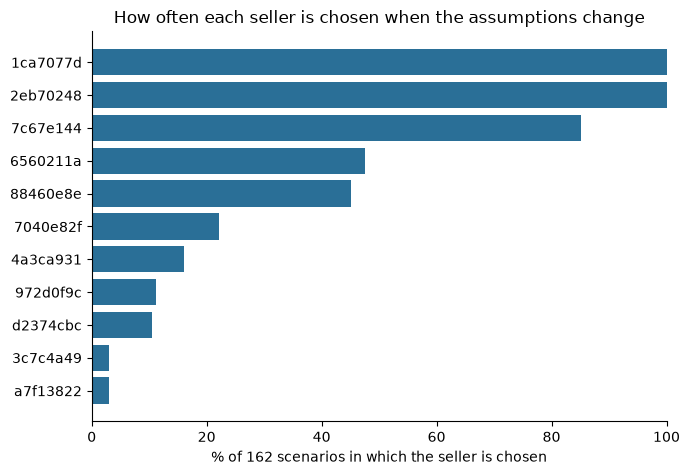

In [12]:
import matplotlib.pyplot as plt

shown = pick_share[pick_share > 0].sort_values()
fig, ax = plt.subplots(figsize=(7, 0.35 * len(shown) + 1))
ax.barh(shown.index, 100 * shown.values, color="#2a6f97")
ax.set_xlabel(f"% of {n_runs} scenarios in which the seller is chosen")
ax.set_title("How often each seller is chosen when the assumptions change")
ax.set_xlim(0, 100)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 8. The ranked shortlist
Sellers ranked by how often they are chosen across scenarios, then by value for money under the
main assumptions. **Tiers:** *core* = chosen in 80%+ of scenarios, *often* = 40-80%,
*sometimes* = under 40%, *not chosen* = never. Saved to `docs/phase5_seller_shortlist.csv` for the
dashboard (Phase 6) and the A/B test design (Phase 7).

In [13]:
short = cb.join(pick_share).reset_index()
short["tier"] = pd.cut(short["chosen_share"], [-0.01, 0, 0.4, 0.8, 1.0],
                       labels=["not chosen", "sometimes", "often", "core"])
short["in_main_choice"] = short["seller"].isin(chosen)
short = short.sort_values(["chosen_share", "benefit_per_1000"], ascending=False).reset_index(drop=True)
short.index = short.index + 1                                              # rank starts at 1
short.index.name = "rank"

out_cols = ["seller_id", "state", "orders", "unhappy", "rate_pct", "excess", "excess_careful",
            "cost", "benefit", "benefit_per_1000", "chosen_share", "tier", "in_main_choice"]
short[out_cols].round(3).to_csv(ROOT / "docs" / "phase5_seller_shortlist.csv")
print(short["tier"].value_counts().reindex(["core", "often", "sometimes", "not chosen"]).to_string())
short[["seller", "state", "orders", "rate_pct", "excess", "cost", "benefit", "chosen_share", "tier"]].round(2)

tier
core           3
often          2
sometimes      6
not chosen    13


,seller,state,orders,rate_pct,excess,cost,benefit,chosen_share,tier
rank,,,,,,,,,
1,2eb70248,SP,162,45.68,59.80,1453.80,10.05,1.00,core
2,1ca7077d,SP,87,54.02,39.37,1192.84,5.24,1.00,core
3,7c67e144,SP,870,20.46,101.72,1711.90,4.99,0.85,core
4,6560211a,SP,1680,13.15,73.69,2374.71,3.62,0.48,often
5,88460e8e,PR,185,20.00,20.78,1317.56,2.14,0.45,often
6,7040e82f,SP,185,21.62,23.78,1241.35,1.86,0.22,sometimes
7,4a3ca931,SP,1489,11.95,47.44,2140.73,2.18,0.16,sometimes
8,972d0f9c,SC,64,35.94,17.39,1096.13,1.57,0.11,sometimes
9,d2374cbc,SP,458,16.16,33.84,1375.44,1.66,0.10,sometimes


In [14]:
main = cb.loc[chosen]
for share in [0.1, 0.3, 0.5]:                                             # removal share is the least known
    print(f"if a fix removes {share:.0%} of the excess: about {share / REMOVAL_SHARE * main['benefit'].sum():.0f} "
          f"unhappy orders avoided in {PILOT_MONTHS} months, out of {main['orders_per_month'].sum() * PILOT_MONTHS:.0f} "
          f"reviewed on-time orders from the chosen sellers")

if a fix removes 10% of the excess: about 9 unhappy orders avoided in 3 months, out of 595 reviewed on-time orders from the chosen sellers
if a fix removes 30% of the excess: about 26 unhappy orders avoided in 3 months, out of 595 reviewed on-time orders from the chosen sellers
if a fix removes 50% of the excess: about 43 unhappy orders avoided in 3 months, out of 595 reviewed on-time orders from the chosen sellers


**Reading it:** across 162 scenarios only 11 of the 24 sellers are ever chosen.
- **Core (3):** 2eb70248 and 1ca7077d are chosen in every scenario, 7c67e144 in 85%. These are the
  sellers worth testing first, whatever we assume.
- **Often (2):** 6560211a (48%) and 88460e8e (45%): good extra picks if the budget allows.
- **13 sellers are never chosen:** they are worse than usual, but under these assumptions their
  expected benefit is too small for the cost.

How much a fix removes is the least known assumption. At 10-50% the main choice would avoid about
9-43 unhappy orders in 3 months, among about 595 reviewed on-time orders. Numbers this small mean a
pilot of this size may be too small to show a clear effect on its own; Phase 7 works out how many
orders a fair test would need.

## 9. Summary
- **Candidates:** 24 sellers worse than the usual 8.77% on-time unhappy rate beyond chance, with 686
  excess unhappy orders between them; the 5 biggest hold 47%.
- **Main choice (budget 8,000 units, up to 6 sellers):** 5 sellers, expected to avoid about 25.8 unhappy
  orders in a 3-month pilot if a fix removes 30% of their excess.
- **Model vs simple rules:** the model avoids the most; "worst rate first" does worst here (19.6).
- **Shortlist worth testing:** 3 core sellers chosen in 85-100% of 162 scenarios, 2 more about half
  the time. Saved to `docs/phase5_seller_shortlist.csv`.

## 10. Limitations
1. **Costs and benefits are assumptions,** not data. The real cost of a pilot and how much it helps are
   unknown; only a test can tell.
2. **Past excess may not continue.** A seller's next 3 months may differ from their history, and very
   high rates tend to move back towards usual on their own (*regression to the mean*), so a
   before-and-after comparison would overstate any effect. That is why Phase 7 uses a comparison group.
3. **Only on-time, single-seller, reviewed orders** are counted, so orders per month (and the
   per-order cost) are lower than each seller's real volume.
4. **Excess per month favours sellers with short histories,** because the same excess over fewer
   months counts as more per month.
5. **Being chosen is not proof the seller causes the unhappiness:** products, customers and regions
   differ between sellers too.